# Milestone 3 - Analysis: ResNet34 U-Net + scratch model, TTA, ensemble, gates

- the new **ResNet34 U-Net** (`r34`) next to the scratch model;
- two possible **gates** per class: the most confident pixel (`maxp`) or the **classification head** probability (`cls`, r34 only); the search picks the better one;
- **ensembles** of r34 and scratch (probability average, weights 1:1 and 2:1), all with flip-TTA;
- objective = reading **B** (per-pair reading), which tracked the leaderboard best (held-out B 0.5836 predicted 0.560 for the last submission, so the leaderboard runs about 0.023 below held-out B);
- a held-out check (tune on one half of the images, score on the other half).

## 0. Setup

In [1]:
import os, glob, time, json, itertools
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

IMG_H, IMG_W = 128, 800
DEFECTS = ["defect_a", "defect_b", "defect_c", "defect_d"]
BS = 16
R34_NAME = "best_r34.pt"            # or "last_r34.pt" to analyse the final-epoch weights
OBJ_MODE = "B"                      # tuning objective: "B", "A" or "mix"
LB_OFFSET = 0.023                   # leaderboard was 0.023 below held-out B on the last submission

def find_file(name, known=None):
    if known and os.path.exists(known):
        return known
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found - attach the right input to this notebook")
    return sorted(hits)[0]

def find_image_dir(sample_id):
    hits = glob.glob(f"/kaggle/input/**/{sample_id}.*", recursive=True)
    if not hits:
        raise FileNotFoundError(f"image {sample_id} not found - attach the competition data")
    return os.path.dirname(hits[0])

TRAIN_CSV = find_file("train.csv", "/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")
HOLDOUT_CSV = find_file("holdout.csv", "/kaggle/input/notebooks/mruniksurya/milestone-1/holdout.csv")
CKPT_SCRATCH = find_file("best_unet_scratch.pt", "/kaggle/input/notebooks/mruniksurya/milestone-2/best_unet_scratch.pt")
CKPT_R34 = find_file(R34_NAME, f"/kaggle/input/notebooks/mruniksurya/milestone-3-r34/{R34_NAME}")
print(CKPT_SCRATCH); print(CKPT_R34)

/kaggle/input/notebooks/mruniksurya/milestone-2/best_unet_scratch.pt
/kaggle/input/notebooks/mruniksurya/miltestone-3-r34-unet/best_r34.pt


## 1. Code blocks (RLE, models, preprocessing, metric, post-processing, search)
Model classes are identical to the training notebooks so the saved weights load.

In [2]:
def rle_decode(rle, shape=(IMG_H, IMG_W)):
    """1-based, column-major RLE string -> binary (H, W) mask. NaN / blank -> all zeros."""
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        tok = np.array(rle.split(), dtype=np.int64)
        starts = tok[0::2] - 1
        ends = starts + tok[1::2]
        for s, e in zip(starts, ends):
            flat[max(s, 0):min(e, flat.size)] = 1
    return flat.reshape(shape, order="F")

def rle_encode(mask):
    """Binary (H, W) mask -> RLE string (1-based, column-major). Empty mask -> empty string."""
    flat = np.asarray(mask).flatten(order="F")
    padded = np.concatenate([[0], flat, [0]])
    k = np.where(padded[1:] != padded[:-1])[0] + 1
    return " ".join(f"{s} {e - s}" for s, e in zip(k[0::2], k[1::2]))

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet34

class DoubleConv(nn.Module):
    """(Conv3x3 -> BatchNorm -> ReLU) x 2 : the basic U-Net building block."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class UNetScratch(nn.Module):
    """Milestone-2 scratch model: 4 encoder levels, 1 input channel, 4 logits. 7,762,564 parameters."""
    def __init__(self, in_ch=1, n_classes=4, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc1, self.enc2 = DoubleConv(in_ch, c[0]), DoubleConv(c[0], c[1])
        self.enc3, self.enc4 = DoubleConv(c[1], c[2]), DoubleConv(c[2], c[3])
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(c[3], c[4])
        self.up4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, stride=2), DoubleConv(c[3] * 2, c[3])
        self.up3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, stride=2), DoubleConv(c[2] * 2, c[2])
        self.up2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, stride=2), DoubleConv(c[1] * 2, c[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, stride=2), DoubleConv(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], n_classes, kernel_size=1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

class UpBlock(nn.Module):
    """Upsample to the skip's size, concatenate, DoubleConv."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = DoubleConv(in_ch + skip_ch, out_ch)
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="nearest")
        return self.conv(torch.cat([x, skip], dim=1))

class ResNetUNet(nn.Module):
    """Milestone-3 model: ResNet34 encoder (1 gray channel) + U-Net decoder + image-level classification head.
    forward(x) -> (segmentation logits (B,4,H,W), classification logits (B,4)). Identical to the training notebook."""
    def __init__(self, base, n_classes=4):
        super().__init__()
        w = base.conv1.weight.data.sum(dim=1, keepdim=True)
        conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        conv1.weight.data.copy_(w)
        self.stem = nn.Sequential(conv1, base.bn1, base.relu)
        self.pool = base.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = base.layer1, base.layer2, base.layer3, base.layer4
        self.up3 = UpBlock(512, 256, 256)
        self.up2 = UpBlock(256, 128, 128)
        self.up1 = UpBlock(128, 64, 64)
        self.up0 = UpBlock(64, 64, 32)
        self.final = DoubleConv(32, 16)
        self.head = nn.Conv2d(16, n_classes, kernel_size=1)
        self.cls_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(512, n_classes))
    def forward(self, x):
        e0 = self.stem(x)
        e1 = self.layer1(self.pool(e0))
        e2 = self.layer2(e1)
        e3 = self.layer3(e2)
        e4 = self.layer4(e3)
        d = self.up3(e4, e3)
        d = self.up2(d, e2)
        d = self.up1(d, e1)
        d = self.up0(d, e0)
        d = F.interpolate(d, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.head(self.final(d)), self.cls_head(e4)

In [4]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', DEVICE)

IMG_MEAN, IMG_STD = 0.3314, 0.1892      # training-set statistics shared by the scratch and r34 models

def to_input(u8):
    """u8: (B,H,W) uint8 gray -> (B,1,H,W) float tensor, (pixel/255 - mean)/std. Used by BOTH models."""
    x = torch.from_numpy(np.ascontiguousarray(u8)).float().div_(255.0)
    return ((x - IMG_MEAN) / IMG_STD).unsqueeze(1)

@torch.no_grad()
def predict(model, u8, tta=False):
    """Returns (probabilities (B,4,H,W), classification probabilities (B,4) or None) on the GPU.
    tta=True averages the plain image with its horizontal and vertical flip."""
    x = to_input(u8).to(DEVICE)
    def fwd(inp):
        out = model(inp)
        if isinstance(out, tuple):
            return torch.sigmoid(out[0]), torch.sigmoid(out[1])
        return torch.sigmoid(out), None
    p, c = fwd(x)
    if tta:
        for dim in (-1, -2):
            p2, c2 = fwd(x.flip(dim))
            p = p + p2.flip(dim)
            if c is not None:
                c = c + c2
        p = p / 3.0
        c = None if c is None else c / 3.0
    return p, c

def load_model(kind, ckpt):
    if kind == "scratch":
        m = UNetScratch(in_ch=1, n_classes=4, base=32)
    elif kind == "r34":
        m = ResNetUNet(resnet34(weights=None))          # architecture only; the weights come from the checkpoint
    else:
        raise ValueError(kind)
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return m.to(DEVICE).eval()

device: cuda


In [5]:
CANVAS_PIXELS = IMG_H * IMG_W

def dice_empty_aware(inter, pred_area, gt_area):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    denom = pred_area + gt_area
    dice = np.where(denom > 0, 2 * inter / np.maximum(denom, 1), 0.0)
    return np.where((pred_area == 0) & (gt_area == 0), 1.0, dice)

def competition_score(inter, pred_area, gt_area, canvas=CANVAS_PIXELS, weights=(0.70, 0.20, 0.10)):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    positive = gt_area > 0
    empty = ~positive
    dice = dice_empty_aware(inter, pred_area, gt_area)
    fg = dice[positive].mean()
    fp = 1 - (pred_area[empty] / canvas).mean()
    ea = (pred_area[empty] == 0).mean()
    return {"foreground_dice": fg, "false_positive_score": fp, "empty_accuracy": ea,
            "score": weights[0] * fg + weights[1] * fp + weights[2] * ea}

In [6]:
import cv2

def postprocess(prob, tau, min_area, gate, gate_score=None):
    """prob (H,W) of ONE (image, class) pair -> binary uint8 mask.
    gate_score: the value compared with the gate: the classification probability, or (default) the most confident pixel.
    If it is below the gate the whole mask is emptied. min_area: regions (8-connectivity) smaller than this are removed."""
    score = prob.max() if gate_score is None else gate_score
    if score < gate:
        return np.zeros(prob.shape, dtype=np.uint8)
    mask = (prob > tau).astype(np.uint8)
    if min_area > 0 and mask.any():
        n, lab, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
        keep = np.zeros(n, dtype=bool)
        keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= min_area
        mask = keep[lab].astype(np.uint8)
    return mask

In [7]:
def both_scores(inter, pred_area, gt_area, rows=None):
    """A = area-based reading (helper formula). B = per-pair reading 0.7*FG Dice + 0.3*empty accuracy.
    On the leaderboard B tracked the real scores much better than A."""
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    if rows is not None:
        inter, pred_area, gt_area = inter[rows], pred_area[rows], gt_area[rows]
    m = competition_score(inter.ravel(), pred_area.ravel(), gt_area.ravel())
    return dict(A=m["score"], B=0.7 * m["foreground_dice"] + 0.3 * m["empty_accuracy"],
                fg=m["foreground_dice"], fp=m["false_positive_score"], ea=m["empty_accuracy"])

def auc_score(score, label):
    """P(random positive pair scores higher than random empty pair); ties count half."""
    score, label = np.asarray(score, dtype=np.float64), np.asarray(label, dtype=bool)
    order = np.argsort(score, kind="mergesort")
    _, inv, counts = np.unique(score[order], return_inverse=True, return_counts=True)
    ranks = np.empty(len(score)); ranks[order] = (np.cumsum(counts) - (counts - 1) / 2.0)[inv]
    n1, n0 = label.sum(), (~label).sum()
    return float((ranks[label].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def build_tables(P, GT, tau):
    """Measure every predicted connected region once: pair id (= image*4 + class), area, truly-defect pixels."""
    pair, area, inter = [], [], []
    for i in range(P.shape[0]):
        for k in range(4):
            pred = (P[i, k].astype(np.float32) > tau).astype(np.uint8)
            if pred.any():
                num, lab, stats, _ = cv2.connectedComponentsWithStats(pred, connectivity=8)
                a = stats[1:, cv2.CC_STAT_AREA].astype(np.int64)
                c = np.bincount(lab[GT[i, k]], minlength=num)[1:].astype(np.int64)
                pair.append(np.full(a.size, i * 4 + k)); area.append(a); inter.append(c)
    if not pair:
        z = np.zeros(0, dtype=np.int64)
        return dict(pair=z, area=z, inter=z)
    return dict(pair=np.concatenate(pair), area=np.concatenate(area), inter=np.concatenate(inter))

def apply_params(T, gate_score, N, G):
    """Apply per-class min area N[k] and gate G[k]. gate_score: (n,4) array (max probability or classification probability)."""
    cls = T["pair"] % 4
    keep = (T["area"] >= np.asarray(N)[cls]) & (gate_score.ravel()[T["pair"]] >= np.asarray(G)[cls])
    size = gate_score.size
    pa = np.bincount(T["pair"][keep], weights=T["area"][keep], minlength=size)
    it = np.bincount(T["pair"][keep], weights=T["inter"][keep], minlength=size)
    return it.reshape(-1, 4), pa.reshape(-1, 4)

N_GRID = [0, 25, 50, 100, 200, 300, 500, 800, 1200, 2000]
G_GRIDS = {"maxp": [0.0, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 0.995, 0.999],
           "cls":  [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]}

def objective(s, mode):
    return s["B"] if mode == "B" else (s["A"] if mode == "A" else 0.5 * (s["A"] + s["B"]))

def tune(T, gate_score, gt_area, rows, mode, g_grid, passes=2):
    """Coordinate search over (min_area, gate) per class."""
    N, G = [0] * 4, [0.0] * 4
    def score(N_, G_):
        it, pa = apply_params(T, gate_score, N_, G_)
        return objective(both_scores(it, pa, gt_area, rows), mode)
    best = score(N, G)
    for _ in range(passes):
        improved = False
        for k in range(4):
            for n_ in N_GRID:
                for g_ in g_grid:
                    N2, G2 = list(N), list(G); N2[k], G2[k] = n_, g_
                    o = score(N2, G2)
                    if o > best + 1e-9:
                        best, N, G, improved = o, N2, G2, True
        if not improved:
            break
    return N, G, best

In [8]:
TAUS_SEARCH = [0.5, 0.7]

def analyse(name, P, config, gates):
    """gates: dict gate_source -> (n,4) score array, e.g. {"maxp": ..., "cls": ...}. Tries every gate source and tau."""
    n = P.shape[0]
    pos = GT_AREA > 0
    pred = P > 0.5
    raw = both_scores((pred & GT).sum(axis=(2, 3)), pred.sum(axis=(2, 3)), GT_AREA)
    del pred

    tables = {tau: build_tables(P, GT, tau) for tau in TAUS_SEARCH}
    best = None
    for gs, gate_arr in gates.items():
        for tau in TAUS_SEARCH:
            N, G, o = tune(tables[tau], gate_arr, GT_AREA, None, OBJ_MODE, G_GRIDS[gs])
            if best is None or o > best["obj"]:
                best = dict(gs=gs, tau=tau, N=N, G=G, obj=o)
    gs, tau, N, G = best["gs"], best["tau"], best["N"], best["G"]
    T, gate_arr = tables[tau], gates[gs]
    it, pa = apply_params(T, gate_arr, N, G)
    tuned = both_scores(it, pa, GT_AREA)

    rng = np.random.default_rng(0)
    half = np.zeros(n, dtype=bool); half[rng.permutation(n)[: n // 2]] = True
    held, held_raw = [], []
    it0, pa0 = apply_params(T, gate_arr, [0] * 4, [0.0] * 4)
    for train_rows in (half, ~half):
        N2, G2, _ = tune(T, gate_arr, GT_AREA, train_rows, OBJ_MODE, G_GRIDS[gs])
        it2, pa2 = apply_params(T, gate_arr, N2, G2)
        held.append(both_scores(it2, pa2, GT_AREA, ~train_rows))
        held_raw.append(both_scores(it0, pa0, GT_AREA, ~train_rows))
    avg = lambda L, key: float(np.mean([d[key] for d in L]))

    oracle = both_scores(it, np.where(pos, pa, 0), GT_AREA)
    detected = pos & (it > 0)
    dice_det = dice_empty_aware(it[detected], pa[detected], GT_AREA[detected]).mean() if detected.any() else 0.0
    return dict(name=name, gate_source=gs, raw_A=raw["A"], raw_B=raw["B"], tau=tau, N=N, G=G,
                tuned_A=tuned["A"], tuned_B=tuned["B"], tuned_fg=tuned["fg"], tuned_ea=tuned["ea"],
                held_A=avg(held, "A"), held_B=avg(held, "B"), heldraw_B=avg(held_raw, "B"),
                oracle_gate_B=oracle["B"], recall_pairs=float(detected.sum() / pos.sum()), dice_when_detected=float(dice_det),
                auc={g: [auc_score(a[:, k], pos[:, k]) for k in range(4)] for g, a in gates.items()},
                pred_pos_rate=[float((pa[:, k] > 0).mean()) for k in range(4)],
                config=dict(config, gate_source=gs, tau=float(tau), min_area=[int(v) for v in N], gate=[float(v) for v in G]))

## 2. Validation images and ground truth (loaded once)

In [9]:
hold = pd.read_csv(HOLDOUT_CSV)
val_ids = sorted(set(hold.loc[hold["split"].astype(str).str.lower().isin({"val", "valid", "validation", "holdout"}), "image_id"]))
assert len(val_ids) == 2279, len(val_ids)
long = pd.read_csv(TRAIN_CSV)
rle_table = long.pivot(index="image_id", columns="defect_type", values="mask_rle")[DEFECTS]

IMG_DIR = find_image_dir(val_ids[0])
files = {os.path.splitext(f)[0]: f for f in os.listdir(IMG_DIR)}
n = len(val_ids)
IMGS = np.zeros((n, IMG_H, IMG_W), dtype=np.uint8)
GT = np.zeros((n, 4, IMG_H, IMG_W), dtype=bool)
for i, iid in enumerate(val_ids):
    g = cv2.imread(os.path.join(IMG_DIR, files[iid]), cv2.IMREAD_GRAYSCALE)
    assert g is not None and g.shape == (IMG_H, IMG_W)
    IMGS[i] = g
    for k, d in enumerate(DEFECTS):
        GT[i, k] = rle_decode(rle_table.at[iid, d])
GT_AREA = GT.sum(axis=(2, 3))
print("images:", IMGS.shape, "| pairs:", GT_AREA.size, "| true empty rate:", round(float((GT_AREA == 0).mean()), 4))

images: (2279, 128, 800) | pairs: 9116 | true empty rate: 0.8419


## 3. Predictions (cached): scratch and r34, plain and with flip-TTA
`S` scratch, `R` r34; `_tta` = average of the plain image and its horizontal and vertical flips. The r34 model also returns classification probabilities (`C` arrays, shape (n,4)).

In [10]:
def predict_all(kind, ckpt, tta):
    model = load_model(kind, ckpt)
    P = np.empty((n, 4, IMG_H, IMG_W), dtype=np.float16)
    C = np.zeros((n, 4), dtype=np.float32) if kind == "r34" else None
    for s in range(0, n, BS):
        p, c = predict(model, IMGS[s:s + BS], tta)
        P[s:s + BS] = p.half().cpu().numpy()
        if C is not None:
            C[s:s + BS] = c.float().cpu().numpy()
    del model; torch.cuda.empty_cache()
    return P, C

BASE, CLS = {}, {}
for key, kind, ckpt, tta in [("S", "scratch", CKPT_SCRATCH, False), ("R", "r34", CKPT_R34, False),
                             ("S_tta", "scratch", CKPT_SCRATCH, True), ("R_tta", "r34", CKPT_R34, True)]:
    t0 = time.time()
    BASE[key], CLS[key] = predict_all(kind, ckpt, tta)
    print(f"{key}: done in {time.time() - t0:.0f}s")

S: done in 24s
R: done in 17s
S_tta: done in 61s
R_tta: done in 42s


## 4. Do the models reproduce their training-time validation scores?

In [11]:
def raw_scores(P, tau=0.5):
    pred = P > tau
    return both_scores((pred & GT).sum(axis=(2, 3)), pred.sum(axis=(2, 3)), GT_AREA)

s = raw_scores(BASE["S"])
print(f"scratch @0.5: A {s['A']:.4f} (training log 0.6020) -> {'OK' if abs(s['A'] - 0.6020) < 0.01 else 'CHECK PREPROCESSING'}")
r = raw_scores(BASE["R"])
print(f"r34     @0.5: A {r['A']:.4f} B {r['B']:.4f} fg {r['fg']:.4f} ea {r['ea']:.3f}")
hits = glob.glob("/kaggle/input/**/m3_r34_history.csv", recursive=True)
if hits and R34_NAME == "best_r34.pt":
    h = pd.read_csv(hits[0]); b = h.loc[(0.5 * (h["A"] + h["B"])).idxmax()]
    print(f"training log best epoch {int(b['epoch'])}: A {b['A']:.4f} B {b['B']:.4f} fg {b['fg']:.4f} -> {'OK' if abs(b['A'] - r['A']) < 0.01 else 'CHECK'}")

scratch @0.5: A 0.6020 (training log 0.6020) -> OK
r34     @0.5: A 0.7189 B 0.6644 fg 0.6383 ea 0.725
training log best epoch 19: A 0.7189 B 0.6644 fg 0.6383 -> OK


## 5. Per-class diagnosis at tau 0.5, and how well each gate separates real defects from empty pairs
`auc_maxp`: AUC of the most confident pixel. `auc_cls`: AUC of the classification head (r34 only). Higher means a gate can remove false alarms without losing real defects.

In [12]:
def diag(P, C=None, tau=0.5):
    pred = P > tau
    pa, it = pred.sum(axis=(2, 3)), (pred & GT).sum(axis=(2, 3))
    maxp = P.max(axis=(2, 3)).astype(np.float32)
    rows = []
    for k, d in enumerate(DEFECTS):
        pos = GT_AREA[:, k] > 0
        row = dict(cls=d, true_pos_rate=pos.mean(), pred_pos_rate=(pa[:, k] > 0).mean(), recall_pairs=(it[pos, k] > 0).mean(),
                   fg_dice=dice_empty_aware(it[pos, k], pa[pos, k], GT_AREA[pos, k]).mean(), empty_acc=(pa[~pos, k] == 0).mean(),
                   auc_maxp=auc_score(maxp[:, k], pos))
        if C is not None:
            row["auc_cls"] = auc_score(C[:, k], pos)
        rows.append(row)
    return pd.DataFrame(rows).set_index("cls").round(3)

for key, label in [("S", "scratch"), ("R", "r34")]:
    print(f"--- {label} (plain, tau 0.5)"); print(diag(BASE[key], CLS[key]).to_string()); print()

--- scratch (plain, tau 0.5)
          true_pos_rate  pred_pos_rate  recall_pairs  fg_dice  empty_acc  auc_maxp
cls                                                                               
defect_a          0.095          0.625         0.676    0.340      0.397     0.711
defect_b          0.028          0.600         0.667    0.336      0.407     0.721
defect_c          0.360          0.762         0.896    0.549      0.341     0.831
defect_d          0.150          0.694         0.965    0.613      0.357     0.901

--- r34 (plain, tau 0.5)
          true_pos_rate  pred_pos_rate  recall_pairs  fg_dice  empty_acc  auc_maxp  auc_cls
cls                                                                                        
defect_a          0.095          0.360         0.741    0.447      0.692     0.849    0.929
defect_b          0.028          0.321         0.825    0.458      0.697     0.895    0.965
defect_c          0.360          0.620         0.941    0.655      0.574     0.

## 6. Candidates: tune threshold, minimum region size and gate (held-out checked)
For every candidate the search tries both gate sources where available (`maxp`, `cls`) and thresholds 0.5 and 0.7, keeps the best, then repeats the tuning on one half of the images and scores it on the other half. Expect roughly 10 to 20 minutes.

In [13]:
def cand_probs(keys, weights):
    w = np.asarray(weights, dtype=np.float32); w = w / w.sum()
    acc = BASE[keys[0]].astype(np.float32) * w[0]
    for k, wk in zip(keys[1:], w[1:]):
        acc += BASE[k].astype(np.float32) * wk
    return acc.astype(np.float16) if len(keys) > 1 else BASE[keys[0]]

CANDS = [
    ("r34",                          ["R"],            [1.0],      "R",     dict(models=["r34"],            tta={"r34": False},                  weights=[1.0])),
    ("r34 + flip-TTA",               ["R_tta"],        [1.0],      "R_tta", dict(models=["r34"],            tta={"r34": True},                   weights=[1.0])),
    ("scratch + flip-TTA (ref)",     ["S_tta"],        [1.0],      None,    dict(models=["scratch"],        tta={"scratch": True},               weights=[1.0])),
    ("ensemble r34:scratch 2:1",     ["R_tta", "S_tta"], [2.0, 1.0], "R_tta", dict(models=["r34", "scratch"], tta={"r34": True, "scratch": True}, weights=[2.0, 1.0])),
    ("ensemble r34:scratch 1:1",     ["R_tta", "S_tta"], [1.0, 1.0], "R_tta", dict(models=["r34", "scratch"], tta={"r34": True, "scratch": True}, weights=[1.0, 1.0])),
]
results = []
for name, keys, weights, cls_key, cfg in CANDS:
    t0 = time.time()
    P = cand_probs(keys, weights)
    gates = {"maxp": P.max(axis=(2, 3)).astype(np.float32)}
    if cls_key is not None:
        gates["cls"] = CLS[cls_key]
    r = analyse(name, P, cfg, gates)
    results.append(r)
    print(f"{name:28s} raw B {r['raw_B']:.4f} -> tuned B {r['tuned_B']:.4f} | held-out B {r['held_B']:.4f} (A {r['held_A']:.4f}) | gate {r['gate_source']} tau {r['tau']} | {time.time() - t0:.0f}s")
    del P

r34                          raw B 0.6644 -> tuned B 0.7107 | held-out B 0.7083 (A 0.7210) | gate cls tau 0.5 | 32s
r34 + flip-TTA               raw B 0.6802 -> tuned B 0.7209 | held-out B 0.7190 (A 0.7313) | gate cls tau 0.5 | 30s
scratch + flip-TTA (ref)     raw B 0.4993 -> tuned B 0.5900 | held-out B 0.5863 (A 0.6185) | gate maxp tau 0.5 | 34s
ensemble r34:scratch 2:1     raw B 0.6750 -> tuned B 0.7168 | held-out B 0.7162 (A 0.7274) | gate cls tau 0.5 | 80s
ensemble r34:scratch 1:1     raw B 0.6481 -> tuned B 0.6964 | held-out B 0.6934 (A 0.7029) | gate cls tau 0.5 | 72s


## 7. Summary
`est_LB` = held-out B minus the observed leaderboard offset (0.023). It is only an estimate (the leaderboard formula is not exactly reading B). `gap_to_0.65` is how far that estimate is from the viva cut-off.

                  candidate  gate  tau   raw_B  held_A  held_B      fg  empty_acc  recall  dice_found  est_LB  gap_to_0.65
0            r34 + flip-TTA   cls  0.5  0.6802  0.7313  0.7190  0.6242     0.9463  0.8522      0.7325  0.6960      -0.0460
1  ensemble r34:scratch 2:1   cls  0.5  0.6750  0.7274  0.7162  0.6180     0.9472  0.8501      0.7270  0.6932      -0.0432
2                       r34   cls  0.5  0.6644  0.7210  0.7083  0.6160     0.9317  0.8536      0.7217  0.6853      -0.0353
3  ensemble r34:scratch 1:1   cls  0.5  0.6481  0.7029  0.6934  0.5870     0.9518  0.8355      0.7026  0.6704      -0.0204
4  scratch + flip-TTA (ref)  maxp  0.5  0.4993  0.6185  0.5863  0.4846     0.8360  0.7425      0.6527  0.5633       0.0867


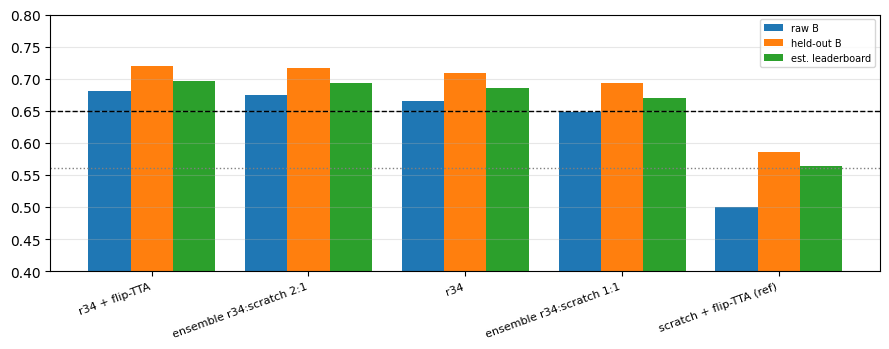


best candidate: r34 + flip-TTA
CONFIG for the inference notebook (Python syntax):
{'models': ['r34'], 'tta': {'r34': True}, 'weights': [1.0], 'gate_source': 'cls', 'tau': 0.5, 'min_area': [100, 50, 200, 200], 'gate': [0.1, 0.2, 0.2, 0.2]}


In [14]:
S_ = pd.DataFrame([dict(candidate=r["name"], gate=r["gate_source"], tau=r["tau"], raw_B=r["raw_B"], held_A=r["held_A"], held_B=r["held_B"],
                        fg=r["tuned_fg"], empty_acc=r["tuned_ea"], recall=r["recall_pairs"], dice_found=r["dice_when_detected"]) for r in results])
S_["est_LB"] = S_["held_B"] - LB_OFFSET
S_["gap_to_0.65"] = 0.65 - S_["est_LB"]
S_ = S_.sort_values("held_B", ascending=False).reset_index(drop=True)
print(S_.round(4).to_string())
S_.round(5).to_csv("/kaggle/working/analysis_m3_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(S_)); w = 0.27
ax.bar(x - w, S_["raw_B"], w, label="raw B"); ax.bar(x, S_["held_B"], w, label="held-out B"); ax.bar(x + w, S_["est_LB"], w, label="est. leaderboard")
ax.axhline(0.65, color="k", ls="--", lw=1); ax.axhline(0.56021, color="gray", ls=":", lw=1)
ax.set_xticks(x); ax.set_xticklabels(S_["candidate"], rotation=20, ha="right", fontsize=8); ax.set_ylim(0.4, 0.8)
ax.legend(fontsize=7); ax.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.savefig("/kaggle/working/analysis_m3_candidates.png", dpi=130); plt.show()

by_name = {r["name"]: r for r in results}
configs = {r["name"]: r["config"] for r in results}
json.dump(configs, open("/kaggle/working/post_configs_m3.json", "w"), indent=1)
best_name = S_.loc[0, "candidate"]
print("\nbest candidate:", best_name)
print("CONFIG for the inference notebook (Python syntax):")
print(repr(configs[best_name]))

## 8. Headroom and gates
`oracle_gate_B`: score if every empty pair were predicted perfectly empty. `auc_*`: separability of real defects from empty pairs for each gate source, per class a, b, c, d.

In [15]:
H = pd.DataFrame([dict(candidate=r["name"], tuned_B=r["tuned_B"], oracle_gate_B=r["oracle_gate_B"], recall=r["recall_pairs"],
                       dice_found=r["dice_when_detected"]) for r in results]).set_index("candidate")
print(H.round(3).to_string()); print()
for r in results:
    print(r["name"])
    for g, a in r["auc"].items():
        print(f"   auc_{g}: {[round(v, 3) for v in a]}")
    print(f"   chosen: gate={r['gate_source']} tau={r['tau']} min_area={r['N']} gate_values={[round(g, 3) for g in r['G']]}")
    print(f"   predicted positive rate {[round(v, 3) for v in r['pred_pos_rate']]} (true {[round(float((GT_AREA[:, k] > 0).mean()), 3) for k in range(4)]})")

                          tuned_B  oracle_gate_B  recall  dice_found
candidate                                                           
r34                         0.711          0.731   0.854       0.722
r34 + flip-TTA              0.721          0.737   0.852       0.733
scratch + flip-TTA (ref)    0.590          0.639   0.743       0.653
ensemble r34:scratch 2:1    0.717          0.733   0.850       0.727
ensemble r34:scratch 1:1    0.696          0.711   0.836       0.703

r34
   auc_maxp: [0.849, 0.895, 0.923, 0.969]
   auc_cls: [0.929, 0.965, 0.958, 0.987]
   chosen: gate=cls tau=0.5 min_area=[100, 500, 200, 200] gate_values=[0.1, 0.1, 0.1, 0.1]
   predicted positive rate [0.141, 0.039, 0.435, 0.169] (true [0.095, 0.028, 0.36, 0.15])
r34 + flip-TTA
   auc_maxp: [0.87, 0.916, 0.928, 0.974]
   auc_cls: [0.932, 0.967, 0.961, 0.988]
   chosen: gate=cls tau=0.5 min_area=[100, 50, 200, 200] gate_values=[0.1, 0.2, 0.2, 0.2]
   predicted positive rate [0.142, 0.036, 0.397, 0.158] (true

## 9. Error cases for the report (best candidate)

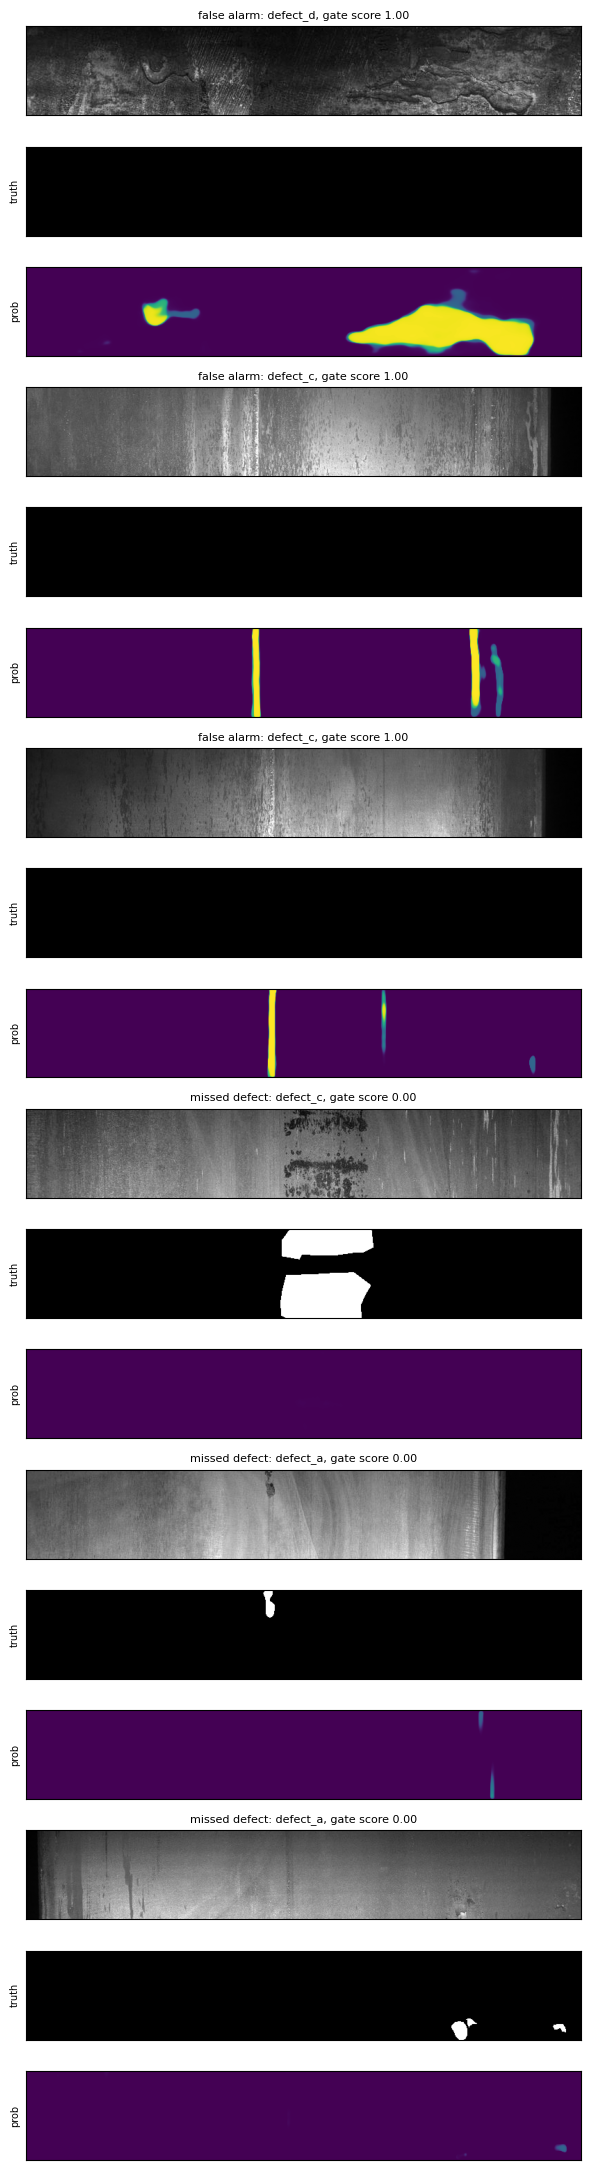

In [16]:
best = by_name[best_name]
cfg = best["config"]
keys = {"r34": "R_tta" if cfg["tta"].get("r34") else "R", "scratch": "S_tta" if cfg["tta"].get("scratch") else "S"}
P_best = cand_probs([keys[m] for m in cfg["models"]], cfg["weights"])
gate_arr = CLS[keys["r34"]] if cfg["gate_source"] == "cls" else P_best.max(axis=(2, 3)).astype(np.float32)
pos = GT_AREA > 0
fp_idx = np.argwhere(~pos)[np.argsort(-gate_arr[~pos])[:3]]
miss_idx = np.argwhere(pos)[np.argsort(gate_arr[pos])[:3]]
cases = [("false alarm", i, k) for i, k in fp_idx] + [("missed defect", i, k) for i, k in miss_idx]
fig, axes = plt.subplots(len(cases) * 3, 1, figsize=(12, 1.1 * len(cases) * 3 + 2))
for c, (kind_, i, k) in enumerate(cases):
    a0, a1, a2 = axes[3 * c], axes[3 * c + 1], axes[3 * c + 2]
    a0.imshow(IMGS[i], cmap="gray"); a0.set_title(f"{kind_}: {DEFECTS[k]}, gate score {gate_arr[i, k]:.2f}", fontsize=8)
    a1.imshow(GT[i, k], cmap="gray", vmin=0, vmax=1); a1.set_ylabel("truth", fontsize=7)
    a2.imshow(P_best[i, k].astype(np.float32), cmap="viridis", vmin=0, vmax=1); a2.set_ylabel("prob", fontsize=7)
    for a in (a0, a1, a2): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig("/kaggle/working/analysis_m3_cases.png", dpi=110); plt.show()